<a href="https://colab.research.google.com/github/mahnooriqbal212/trip-planner-agent-team/blob/main/trip_planner_agent_team.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ✈️ Trip Planner Agent Team (LangGraph Capstone)

**Name:** Mahnoor Iqbal  
**Course:** Python-AI, AshreiTech Academy

A customer asks for a trip. A **team of agents** plans it, a **human approves** it, and the conversation is **saved in SQLite**.

| Member | Type | Job |
|---|---|---|
| `budget_agent` | tool-using agent (ReAct) | checks weather, converts currency, splits the budget |
| `itinerary_agent` | LLM writer | writes a short day-by-day plan |
| `supervisor` | boss | picks who works next: budget → itinerary → FINISH |
| `approval` | human in the loop | `yes`, `no`, or feedback for a rewrite |
| `book_trip` | plain node | pretends to book (only after `yes`) |

```
START → supervisor ──budget────► budget_agent ───────┐
              │   └─itinerary──► itinerary_agent ────┤ (back to supervisor)
              └──FINISH──► approval ──yes──► book_trip → END
                              │ │
                              │ └──no───► cancelled → END
                              └─ feedback ─► itinerary_agent (rewrite)
```

## Step 0: Setup

We use **Groq** (free). The model `openai/gpt-oss-120b` is good at using tools.

👉 In Colab, click the 🔑 **Secrets** icon on the left, add a secret named `GROQ_API_KEY`, and turn on *Notebook access*.

In [3]:
!pip install -q -U langgraph langchain langchain-groq langgraph-checkpoint-sqlite

In [5]:
import os, operator, sqlite3
from typing import TypedDict, Annotated, Literal

from google.colab import userdata
os.environ["GROQ_API_KEY"] = userdata.get("Groq_key")

from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain.agents import create_agent

from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.sqlite import SqliteSaver

# llm0: strict (temperature 0) for the agent and the supervisor
# llm : a bit creative for writing the plan
llm0 = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
llm  = ChatGroq(model="openai/gpt-oss-120b", temperature=0.7)

print(llm0.invoke("Say hello in one short sentence.").content)

Hello!


## Lab step 1: Tools

Two tools with `@tool`. The **docstring is important**: the LLM reads it to know when to use the tool.  
Both tools use **fake data**. An unknown city or currency returns a **message** (no crash).

In [6]:
@tool
def get_weather(city: str) -> str:
    """Get the current weather for a city. Known cities: lahore, karachi, murree."""
    fake_weather = {
        "lahore":  "Lahore: 24°C, sunny, light breeze.",
        "karachi": "Karachi: 28°C, humid, partly cloudy.",
        "murree":  "Murree: 8°C, cold and foggy, light rain possible.",
    }
    return fake_weather.get(
        city.strip().lower(),
        f"Sorry, I have no weather data for '{city}'. Try lahore, karachi or murree.",
    )


@tool
def convert_currency(amount: float, to: str) -> str:
    """Convert an amount from PKR to another currency. Supported targets: USD, EUR, GBP."""
    fake_rates = {"USD": 0.0036, "EUR": 0.0033, "GBP": 0.0028}   # fake rates
    code_ = to.strip().upper()
    if code_ not in fake_rates:
        return f"Error: currency '{to}' is not supported. Use USD, EUR or GBP."
    return f"{amount:,.0f} PKR = {amount * fake_rates[code_]:,.2f} {code_}"


# quick test
print(get_weather.invoke({"city": "Lahore"}))
print(get_weather.invoke({"city": "Paris"}))
print(convert_currency.invoke({"amount": 60000, "to": "USD"}))
print(convert_currency.invoke({"amount": 60000, "to": "JPY"}))

Lahore: 24°C, sunny, light breeze.
Sorry, I have no weather data for 'Paris'. Try lahore, karachi or murree.
60,000 PKR = 216.00 USD
Error: currency 'JPY' is not supported. Use USD, EUR or GBP.


## Lab step 2: The state

The state is the **shared notebook** that all nodes read and write.

- `results` and `tools_used` use the reducer `operator.add`, so new items are **added** to the list (not replaced).
- `steps` counts supervisor turns (for the step limit).
- `revisions` counts how many times the plan was written.

In [7]:
class TripState(TypedDict):
    request: str
    results: Annotated[list, operator.add]
    steps: int
    tools_used: Annotated[list, operator.add]
    itinerary: str
    feedback: str
    revisions: int
    status: str

## Lab step 3: `budget_agent` (tool-using agent)

`create_agent` builds a **ReAct loop**: think → call a tool → read the result → think again → answer.  
The node function runs the agent and saves two things: the **answer** and the **names of the tools it used**.

In [8]:
budget_prompt = """You are a travel budget planner.
- Use the tools. Check the weather of the destination city with get_weather.
- Convert the total budget with convert_currency when the customer asks for another currency.
- Never guess numbers. Take weather and currency numbers only from the tools.
- End with a short cost table in PKR (stay, food, transport, activities, extra) that adds up to the total budget.
- Also write the weather in one line."""

budget_react_agent = create_agent(
    llm0,
    [get_weather, convert_currency],
    system_prompt=budget_prompt,
)


def budget_agent(state: TripState):
    out = budget_react_agent.invoke(
        {"messages": [{"role": "user", "content": state["request"]}]}
    )
    answer = out["messages"][-1].content
    used = [m.name for m in out["messages"] if m.type == "tool"]
    return {"results": [f"budget: {answer}"], "tools_used": used}

## Lab step 4: `itinerary_agent` (writer)

A normal LLM call. If there is **feedback**, we also give the **previous plan** and the **feedback**, so the new plan is a rewrite (not a brand new idea).

In [9]:
def itinerary_agent(state: TripState):
    # take the latest budget result
    budget_text = [r for r in state["results"] if r.startswith("budget:")][-1]

    prompt = f"""You are a travel itinerary writer.
Customer request: {state["request"]}

Budget and weather info:
{budget_text}

Write a short day-by-day plan (Day 1, Day 2, ...). It must fit the budget and match the weather
(mention the weather in the plan). Keep it short and clear."""

    if state.get("feedback"):
        prompt += f"""

Here is your previous plan:
{state["itinerary"]}

The customer gave this feedback: {state["feedback"]}
Rewrite the plan and apply the feedback."""

    plan = llm.invoke(prompt).content
    return {
        "itinerary": plan,
        "results": ["itinerary: done"],
        "revisions": state.get("revisions", 0) + 1,
    }

## Lab step 5: Supervisor

The supervisor asks the LLM: *who works next?* Two safety habits:

1. **Allow-list:** if the LLM answer is not `budget`, `itinerary` or `finish`, we use a safe **default**.
2. **Step limit:** after `MAX_STEPS` turns, we force `finish`.

When the supervisor finishes, it goes to **`approval`** (not `END`).

In [10]:
ALLOWED = ["budget", "itinerary", "finish"]
MAX_STEPS = 6


def supervisor(state: TripState) -> Command[Literal["budget_agent", "itinerary_agent", "approval"]]:
    steps = state.get("steps", 0)
    budget_done = any(r.startswith("budget:") for r in state.get("results", []))
    itinerary_done = bool(state.get("itinerary"))

    # safe default (Python decides what is logical)
    if not budget_done:
        default = "budget"
    elif not itinerary_done:
        default = "itinerary"
    else:
        default = "finish"

    if steps >= MAX_STEPS:                      # step limit
        choice = "finish"
    else:
        prompt = f"""You are the supervisor of a trip planning team.
Workers:
- budget: checks weather, converts currency and splits the budget.
- itinerary: writes the day-by-day plan (needs the budget first).

Order: first budget, then itinerary, then finish.
Budget done: {budget_done}
Itinerary done: {itinerary_done}

Who works next? Answer with ONE word only: budget, itinerary or finish."""
        answer = llm0.invoke(prompt).content.strip().lower()
        choice = answer if answer in ALLOWED else default      # allow-list check

    goto = {"budget": "budget_agent", "itinerary": "itinerary_agent", "finish": "approval"}[choice]
    print(f"[supervisor] step {steps + 1}: choice = {choice} -> {goto}")
    return Command(goto=goto, update={"steps": steps + 1})

## Lab step 6: Approval and booking

- `approval` uses `interrupt(...)`. The graph **stops** here and waits for the human.
- `yes` → `book_trip`, `no` → `cancelled`, **anything else** = feedback → `itinerary_agent` (max 3 revisions).
- The pretend booking is **only** inside `book_trip`, so nothing is booked before `yes`.

When feedback is sent, we reset `steps` to 0 so the supervisor gets a fresh step budget.

In [11]:
MAX_REVISIONS = 3


def approval(state: TripState) -> Command[Literal["book_trip", "cancelled", "itinerary_agent"]]:
    answer = interrupt({
        "plan": state["itinerary"],
        "question": "Type 'yes' to book, 'no' to cancel, or write feedback to change the plan.",
    })
    text = str(answer).strip()

    if text.lower() in ("yes", "y"):
        return Command(goto="book_trip", update={"status": "approved"})

    if text.lower() in ("no", "n"):
        return Command(goto="cancelled", update={"status": "rejected"})

    # anything else is feedback
    if state.get("revisions", 0) >= MAX_REVISIONS:
        return Command(goto="cancelled", update={"status": "too many revisions"})

    return Command(
        goto="itinerary_agent",
        update={"feedback": text, "status": "revising", "steps": 0},
    )


def book_trip(state: TripState):
    # the ONLY place where booking happens (pretend)
    print("✅ BOOKING TRIP... (pretend) Done!")
    return {"status": "booked", "results": ["book_trip: booked"]}


def cancelled(state: TripState):
    print("❌ Trip cancelled. Nothing was booked.")
    return {"results": ["cancelled"]}

## Lab step 7: Build, save and test

We connect all nodes and compile with a **`SqliteSaver`** (a new `.db` file), so memory survives a restart.

> `supervisor` and `approval` choose the next node with `Command(goto=...)`, so we do not need `add_conditional_edges` for them.

In [12]:
builder = StateGraph(TripState)

builder.add_node("supervisor", supervisor)
builder.add_node("budget_agent", budget_agent)
builder.add_node("itinerary_agent", itinerary_agent)
builder.add_node("approval", approval)
builder.add_node("book_trip", book_trip)
builder.add_node("cancelled", cancelled)

builder.add_edge(START, "supervisor")
builder.add_edge("budget_agent", "supervisor")      # workers report back to the boss
builder.add_edge("itinerary_agent", "supervisor")
builder.add_edge("book_trip", END)
builder.add_edge("cancelled", END)

# new database file (delete old one so the test starts fresh)
DB_FILE = "trip_planner.db"
if os.path.exists(DB_FILE):
    os.remove(DB_FILE)

conn = sqlite3.connect(DB_FILE, check_same_thread=False)
graph = builder.compile(checkpointer=SqliteSaver(conn))
print("Graph is ready!")

Graph is ready!


### The mermaid drawing of the graph

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	budget_agent(budget_agent)
	itinerary_agent(itinerary_agent)
	approval(approval)
	book_trip(book_trip)
	cancelled(cancelled)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	approval -.-> book_trip;
	approval -.-> cancelled;
	approval -.-> itinerary_agent;
	budget_agent --> supervisor;
	itinerary_agent --> supervisor;
	supervisor -.-> approval;
	supervisor -.-> budget_agent;
	supervisor -.-> itinerary_agent;
	book_trip --> __end__;
	cancelled --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



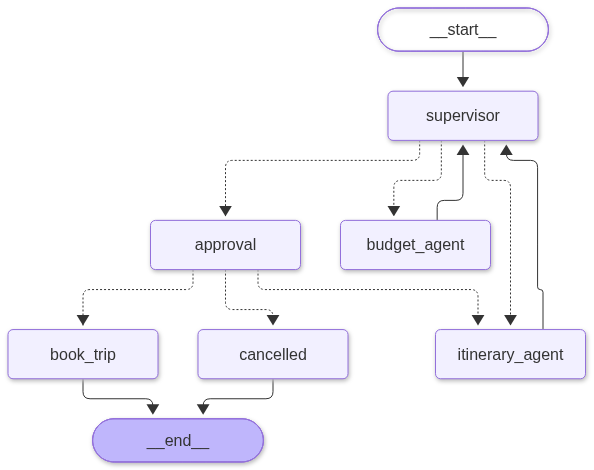

In [16]:
print(graph.get_graph().draw_mermaid())
try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Picture not available here, use the Mermaid text above.")

👆 Copy this text into [mermaid.live](https://mermaid.live) to see the picture.

### Test goal

We use a helper that **streams** (`stream_mode="updates"`) so we can watch each node finish.  
The `thread_id` is the "conversation name" the saver uses to remember things.

In [17]:
config = {"configurable": {"thread_id": "trip-lahore-1"}}

def run(inp):
    for chunk in graph.stream(inp, config, stream_mode="updates"):
        for node in chunk:
            print("▶ finished:", node)

test_input = {
    "request": "3 days in Lahore for 2 people, total budget PKR 60000. Show the budget in USD too.",
    "results": [],
    "steps": 0,
    "tools_used": [],
    "itinerary": "",
    "feedback": "",
    "revisions": 0,
    "status": "start",
}

### Run 1: first run, the graph stops at `approval`

In [18]:
run(test_input)

state = graph.get_state(config)
print("\nNext node waiting:", state.next)      # should be ('approval',)
print("Status:", state.values["status"])
print("\n===== PLAN (revision", state.values["revisions"], ") =====")
print(state.values["itinerary"])

[supervisor] step 1: choice = budget -> budget_agent
▶ finished: supervisor
▶ finished: budget_agent
[supervisor] step 2: choice = itinerary -> itinerary_agent
▶ finished: supervisor
▶ finished: itinerary_agent
[supervisor] step 3: choice = finish -> approval
▶ finished: supervisor
▶ finished: __interrupt__

Next node waiting: ('approval',)
Status: start

===== PLAN (revision 1 ) =====
**3‑Day Lahore Itinerary (2 people) – PKR 60,000 ≈ USD 216**  

| Category | PKR | USD* |
|----------|-----|------|
| Stay | 25,000 | 90 |
| Food | 15,000 | 54 |
| Transport | 8,000 | 29 |
| Activities | 8,000 | 29 |
| Extra (tips, water, souvenirs) | 4,000 | 14 |
| **Total** | **60,000** | **≈ 216** |

\*USD conversion uses 1 USD ≈ 277 PKR (approx).

---

### General notes
* **Weather:** 24 °C, sunny with a light breeze – perfect for walking and outdoor sites.  
* All costs are averages; you can shift a few rupees between categories as you wish.  
* Use a **budget hotel/guesthouse** in the Old City (≈ 1

### Run 2: answer with feedback, the plan must change

In [19]:
run(Command(resume="Add one cheap restaurant to each day."))

state = graph.get_state(config)
print("\nNext node waiting:", state.next)      # approval again
print("\n===== PLAN (revision", state.values["revisions"], ") =====")
print(state.values["itinerary"])

▶ finished: approval
▶ finished: itinerary_agent
[supervisor] step 1: choice = finish -> approval
▶ finished: supervisor
▶ finished: __interrupt__

Next node waiting: ('approval',)

===== PLAN (revision 2 ) =====
**3‑Day Lahore Itinerary (2 people) – PKR 60,000 ≈ USD 216**  

| Category | PKR | USD* |
|----------|-----|------|
| Stay (2 nights) | 25,000 | 90 |
| Food (incl. cheap restaurants) | 15,000 | 54 |
| Transport (rickshaw, metro, taxi) | 8,000 | 29 |
| Activities (entries, boat, etc.) | 8,000 | 29 |
| Extra (tips, water, souvenirs) | 4,000 | 14 |
| **Total** | **60,000** | **≈ 216** |

\*Conversion ≈ 1 USD = 277 PKR (approx).  

**Weather:** 24 °C, sunny with a light breeze – perfect for walking and outdoor sites.  

---

## Day 1 – Arrival & Old‑City Highlights  

| Time | Activity | Approx. Cost (PKR) |
|------|----------|--------------------|
| Morning | Check‑in, freshen up (budget guesthouse in the Old City, ~12,500 PKR/night) | – |
| 10:00 am | Walk to **Lahore Fort** (en

### Run 3: answer `yes`, now the trip is booked

In [20]:
run(Command(resume="yes"))

state = graph.get_state(config)
print("\nStatus:", state.values["status"])
print("Next:", state.next)                       # () means finished

▶ finished: approval
✅ BOOKING TRIP... (pretend) Done!
▶ finished: book_trip

Status: booked
Next: ()


## Proof for the checklist

**1. Did the budget agent use both tools?**

In [21]:
state = graph.get_state(config)
print("tools_used:", state.values["tools_used"])

assert "get_weather" in state.values["tools_used"], "weather tool was not used!"
assert "convert_currency" in state.values["tools_used"], "currency tool was not used!"
print("✅ Both tools were used")

tools_used: ['get_weather', 'convert_currency']
✅ Both tools were used


**2. Did the budget result and plan include weather? Did feedback change the plan? Was booking done only after yes?**

In [22]:
print("Revisions:", state.values["revisions"])   # should be 2
print("Status   :", state.values["status"])      # should be booked
print()
for r in state.values["results"]:
    print("-", r[:120].replace("\n", " "))

Revisions: 2
Status   : booked

- budget: **Weather:** Lahore — 24 °C, sunny, light breeze.    **Budget Overview (PKR 60,000 ≈ USD 216.00)**    | Category
- itinerary: done
- itinerary: done
- book_trip: booked


**3. Does the memory survive a restart?**

We close the connection, open the `.db` file again with a **new** saver and a **new** compiled graph, and read the saved state.

In [23]:
conn.close()                                     # "restart"

conn2 = sqlite3.connect(DB_FILE, check_same_thread=False)
graph2 = builder.compile(checkpointer=SqliteSaver(conn2))

saved = graph2.get_state(config)
print("Status   :", saved.values["status"])
print("Revisions:", saved.values["revisions"])
print("tools_used:", saved.values["tools_used"])
print("\n===== SAVED PLAN =====")
print(saved.values["itinerary"])

Status   : booked
Revisions: 2
tools_used: ['get_weather', 'convert_currency']

===== SAVED PLAN =====
**3‑Day Lahore Itinerary (2 people) – PKR 60,000 ≈ USD 216**  

| Category | PKR | USD* |
|----------|-----|------|
| Stay (2 nights) | 25,000 | 90 |
| Food (incl. cheap restaurants) | 15,000 | 54 |
| Transport (rickshaw, metro, taxi) | 8,000 | 29 |
| Activities (entries, boat, etc.) | 8,000 | 29 |
| Extra (tips, water, souvenirs) | 4,000 | 14 |
| **Total** | **60,000** | **≈ 216** |

\*Conversion ≈ 1 USD = 277 PKR (approx).  

**Weather:** 24 °C, sunny with a light breeze – perfect for walking and outdoor sites.  

---

## Day 1 – Arrival & Old‑City Highlights  

| Time | Activity | Approx. Cost (PKR) |
|------|----------|--------------------|
| Morning | Check‑in, freshen up (budget guesthouse in the Old City, ~12,500 PKR/night) | – |
| 10:00 am | Walk to **Lahore Fort** (entry ≈ 200 PKR per person) | 400 |
| 12:30 pm | **Cheap lunch:** *Al‑Maqam Dhabā* on Food Street – chicken kara

## ✅ Lab checklist

- [x] The budget agent called **both** tools (see `tools_used`)
- [x] The supervisor's answer is **checked** (allow-list) and the loop has a **step limit** (`MAX_STEPS`)
- [x] The graph **stops** for approval and resumes with `Command(resume=...)`
- [x] Feedback produced a **different** plan (revision 2)
- [x] `book_trip` ran **only** after `yes`
- [x] After closing the connection and reopening the `.db` file, `get_state` still shows the plan

## 🧠 Concepts in my own words

- **Fan-out / fan-in:** Fan-out means one node sends work to several nodes at the same time, so they run in parallel. Fan-in means the results from those nodes come back together into one node. In this project the supervisor sends one worker at a time (budget first, then itinerary), and each worker reports back to the supervisor. So it is the fan-in idea (results collected in one place), but not true parallel fan-out.
- **Interrupt:** the graph pauses and saves its place. The human answers, and `Command(resume=...)` continues from the same point.
- **Supervisor:** a boss node that picks which worker goes next. We check its answer and limit the steps so it can never loop forever.
- **Checkpointer:** it saves the state after every step. With `SqliteSaver` the saves are in a file, so they survive a restart.